# **MÓDULO 27 - Projeto de Doenças Cardiovasculares - Regressão Logística**


Assim como na aula que trabalhamos com uma base de dados nova, com um contexto de modelo de propensão a compra de carros, para a atividade de vocês achei interessante trazer também novos desafios.

Nessa tarefa iremos construir um modelo que nos ajude a prever doenças cardiovasculares, a base contém dados reais.

age - idade dos pacientes

gender - genero (0 mulheres) (1 homens)

height - altura dos pacientes

weight - peso dos pacientes

gluc - glicose

smoke - fumante (1) não fumante (0)

alco - consume alcool (1) não consome (0)

active - realiza atividades fisicas (1) não realiza (0)

cardio_disease - tem doença cardio (1) não tem (0) - Variável target


Seu objetivo é utilizar esses dados históricos dos pacientes e construir um bom modelo de regressão capaz de indicar se novos pacientes estão propensos a doenças cariovasculares ou não.

In [1]:
 import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, classification_report

# 1) Comece carregando e tratando a base de dados.
Assim como na aula essa nova base não passou por pré processamento nenhum então nessa etapa, carrega os dados, verifique os tipos de dados, verifique se temos dados faltantes e outliers.
Quando necessário realize o tratamento.


In [2]:
base = pd.read_csv("CARDIO_BASE.csv", delimiter=';', encoding="latin1")

In [3]:
base

,age,gender,height,weight,cholesterol,gluc,smoke,alco,active,cardio_disease
0,50,2,168,62,1,1,0,0,1,0
1,55,1,156,85,3,1,0,0,1,1
2,52,1,165,64,3,1,0,0,0,1
3,48,2,169,82,1,1,0,0,1,1
4,48,1,156,56,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
9995,56,1,166,65,1,1,0,0,0,0
9996,50,1,160,93,2,1,0,0,1,1
9997,40,1,158,66,2,2,0,0,1,0
9998,50,1,168,70,3,1,0,0,1,1


In [4]:
base.describe()

,age,gender,height,cholesterol,gluc,smoke,alco,active,cardio_disease
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,53.288300,1.345400,164.308200,1.365000,1.222200,0.089000,0.053700,0.797200,0.503100
std,6.796234,0.475522,8.178796,0.677658,0.565561,0.284758,0.225436,0.402105,0.500015
min,30.000000,1.000000,70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,1.000000,159.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,165.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
75%,58.000000,2.000000,170.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,65.000000,2.000000,250.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [5]:
base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             10000 non-null  int64 
 1   gender          10000 non-null  int64 
 2   height          10000 non-null  int64 
 3   weight          10000 non-null  object
 4   cholesterol     10000 non-null  int64 
 5   gluc            10000 non-null  int64 
 6   smoke           10000 non-null  int64 
 7   alco            10000 non-null  int64 
 8   active          10000 non-null  int64 
 9   cardio_disease  10000 non-null  int64 
dtypes: int64(9), object(1)
memory usage: 781.4+ KB


In [6]:
base["weight"] = base["weight"].str.replace(",", ".", regex=False).astype(float)

In [7]:
base.describe()

,age,gender,height,weight,cholesterol,gluc,smoke,alco,active,cardio_disease
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,53.288300,1.345400,164.308200,74.303710,1.365000,1.222200,0.089000,0.053700,0.797200,0.503100
std,6.796234,0.475522,8.178796,14.566353,0.677658,0.565561,0.284758,0.225436,0.402105,0.500015
min,30.000000,1.000000,70.000000,30.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,1.000000,159.000000,65.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,165.000000,72.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
75%,58.000000,2.000000,170.000000,82.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,65.000000,2.000000,250.000000,200.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
base["gluc"].unique()
base["cholesterol"].unique()

array([1, 3, 2])

In [9]:
base["gluc"] = base["gluc"].replace([2, 3], 0)

In [10]:
base["cholesterol"] = base["cholesterol"].replace([2, 3], 0)

In [11]:
base["gender"] = base["gender"].replace([2], 0)

In [12]:
base.describe()

,age,gender,height,weight,cholesterol,gluc,smoke,alco,active,cardio_disease
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,53.288300,0.654600,164.308200,74.303710,0.748700,0.85130,0.089000,0.053700,0.797200,0.503100
std,6.796234,0.475522,8.178796,14.566353,0.433782,0.35581,0.284758,0.225436,0.402105,0.500015
min,30.000000,0.000000,70.000000,30.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,159.000000,65.000000,0.000000,1.00000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,165.000000,72.000000,1.000000,1.00000,0.000000,0.000000,1.000000,1.000000
75%,58.000000,1.000000,170.000000,82.000000,1.000000,1.00000,0.000000,0.000000,1.000000,1.000000
max,65.000000,1.000000,250.000000,200.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000


# 2) Agora é hora de explorar os dados com uma análise bem completa.
Plote pelo menos 3 gráficos analisando o comportamento da variável cardio com outras variaveis da sua preferência (análise bivariada). Não se esqueça de trazer insights acerca do analisado.


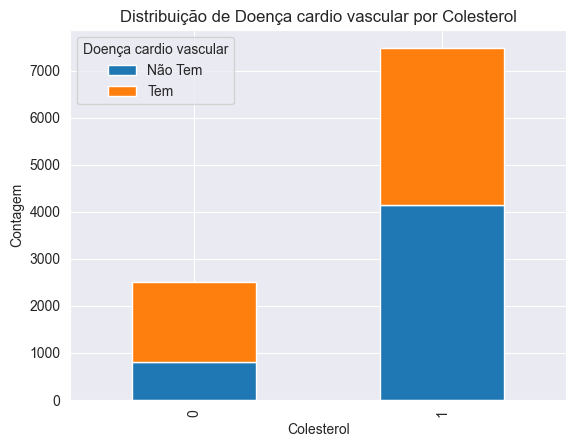

In [13]:
contagem = pd.crosstab(base['cholesterol'], base['cardio_disease'])
contagem.plot(kind='bar', stacked=True)
plt.title('Distribuição de Doença cardio vascular por Colesterol')
plt.xlabel('Colesterol')
plt.ylabel('Contagem')
plt.legend(title='Doença cardio vascular', labels=['Não Tem', 'Tem'])
plt.show()

Podemos notar que um pouco mais da metade dos pacientes que tem colesterol não apresentão nenhuma doença cardiaca. O que indicar que ter colesterol não é necessariamente uma condição para ter doença cardiaca.

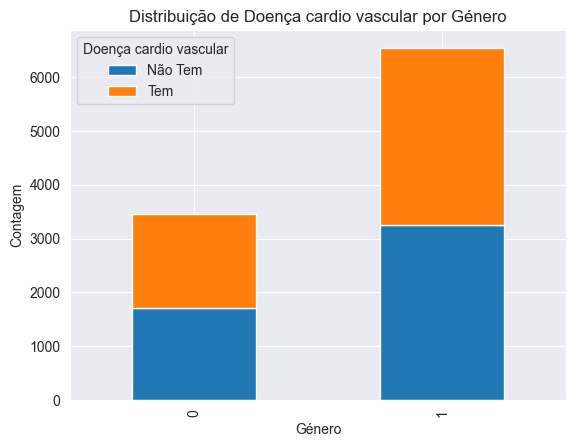

In [14]:
contagem = pd.crosstab(base['gender'], base['cardio_disease'])
contagem.plot(kind='bar', stacked=True)
plt.title('Distribuição de Doença cardio vascular por Género')
plt.xlabel('Género')
plt.ylabel('Contagem')
plt.legend(title='Doença cardio vascular', labels=['Não Tem', 'Tem'])
plt.show()

Apesar de termos mais pacientes do género masculino na base podemos notar que a contagem de doença cardio vascular segue quase no mesmo nivel que o género feminino dado a quantidade de pacientes em cada género.

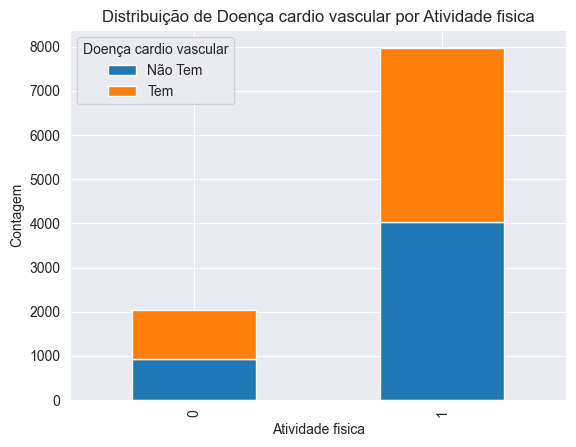

In [15]:
contagem = pd.crosstab(base['active'], base['cardio_disease'])
contagem.plot(kind='bar', stacked=True)
plt.title('Distribuição de Doença cardio vascular por Atividade fisica')
plt.xlabel('Atividade fisica')
plt.ylabel('Contagem')
plt.legend(title='Doença cardio vascular', labels=['Não Tem', 'Tem'])
plt.show()

Metade dos pacientes que praticam atividade fisica contém doenças cardio vasculares.

# 3) Nessa etapa você deve trazer a matriz de correlação e apontar insights acerca das variáveis com um relacionamento mais forte entre si.



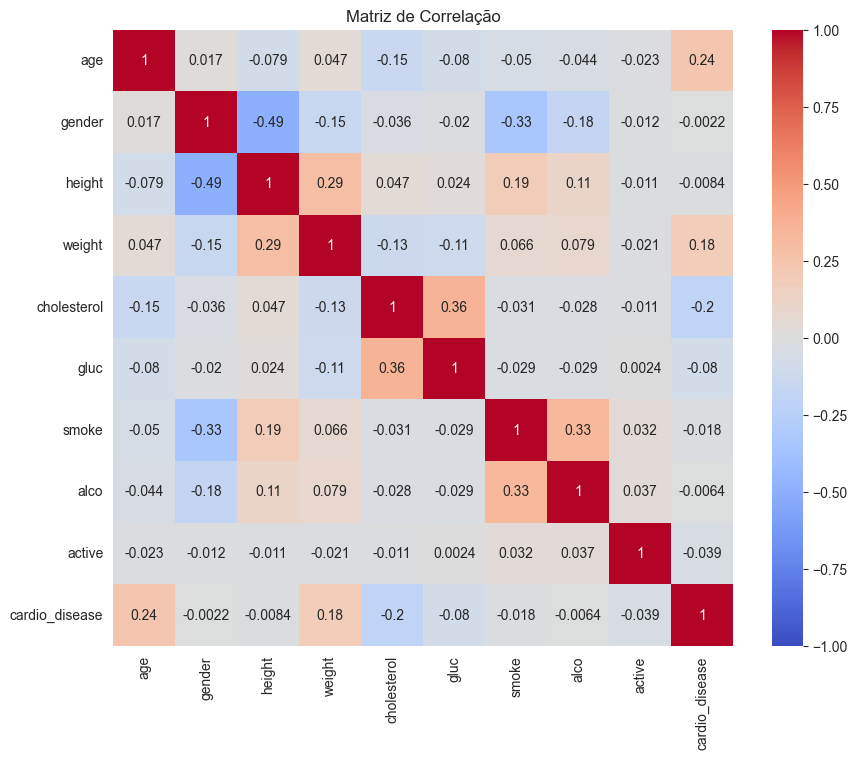

In [16]:
correlation_matrix = base.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlação')
plt.show()

A variavel Age é a que mais apresenta ter correlação com a nossa variavel target Cario_disease. Temos outras variais que também apresentão uma forte correlação como a Alco com smoke, weight com height e Cholesterol com Glug a qual epresenta a maior correlação.

# 4) Essa é a sua última etapa pré modelo. Você deve:

A) Separar a base em treino e teste.

B) Você considera que essa base precisa que os dados sejam padronizados? Se sim, porque? Se acredita que devem, então realize essa etapa.

C) Verifique se os dados estão balanceados, se não, faça o balanceamento.


D) Visualize as bases de treino, teste (X E Y) e verifique se está tudo adequado.

In [17]:
X = base.drop('cardio_disease', axis=1)  
Y = base['cardio_disease'] 

In [18]:
base['cardio_disease'].value_counts()

cardio_disease
1    5031
0    4969
Name: count, dtype: int64

In [19]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [20]:
sc = StandardScaler()

X_train = sc.fit_transform(X_train)

X_test = sc.transform(X_test)

Decidi fazer a padronização dos dados para que totas as features estejam equilibradas.

In [21]:
smote = SMOTE(random_state=42)
X_train_balanced, Y_train_balanced = smote.fit_resample(X_train, Y_train)

In [22]:
X_train_balanced


array([[ 0.10037973,  0.73138185, -1.25610705, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [-0.19393504, -1.36727483,  0.08809078, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [ 1.4247962 ,  0.73138185, -0.27850863, ..., -0.31328402,
        -0.24037742, -1.96927621],
       ...,
       [ 0.98332404, -1.36727483,  0.65429181, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [-0.38309027, -1.36727483,  1.25071897, ...,  3.19199173,
        -0.24037742,  0.50780078],
       [-1.07687935,  0.73138185,  0.84528083, ..., -0.31328402,
        -0.24037742,  0.50780078]], shape=(8064, 9))

In [23]:
Y_train_balanced


0       0
1       0
2       1
3       1
4       0
       ..
8059    0
8060    0
8061    0
8062    0
8063    0
Name: cardio_disease, Length: 8064, dtype: int64

In [24]:
X_test

array([[-0.63540719,  0.73138185, -0.03410902, ..., -0.31328402,
        -0.24037742, -1.96927621],
       [ 0.10037973, -1.36727483,  1.43228861, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [ 0.10037973,  0.73138185, -0.76730784, ..., -0.31328402,
        -0.24037742,  0.50780078],
       ...,
       [-1.66550889,  0.73138185,  0.6990898 , ..., -0.31328402,
        -0.24037742,  0.50780078],
       [-0.48824981,  0.73138185,  0.45469019, ..., -0.31328402,
        -0.24037742,  0.50780078],
       [ 1.27763881, -1.36727483, -0.03410902, ..., -0.31328402,
        -0.24037742,  0.50780078]], shape=(2000, 9))

In [25]:
Y_test

6252    0
4684    0
1731    1
4742    0
4521    1
       ..
6412    1
8285    1
7853    0
1095    1
6929    0
Name: cardio_disease, Length: 2000, dtype: int64

# 5) Realize a etapa de treinamento do modelo:

A) Faça o treinamento do modelo.

B) Traga o intercept e os coeficientes.

c) Avalie as métricas do modelo treinado

D) Justifique se te parece que o modelo tem feito boas previsões ou não.

In [26]:
logistic_cardio = LogisticRegression(random_state = 0)

In [27]:
logistic_cardio.fit(X_train_balanced, Y_train_balanced)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver

In [28]:
logistic_cardio.intercept_

array([0.00770469])

In [30]:
logistic_cardio.coef_

array([[ 0.45308103, -0.01064039, -0.08014436,  0.35392601, -0.33169267,
         0.02505238, -0.02823415, -0.00982407, -0.06735223]])

In [29]:
previsoes = logistic_cardio.predict(X_train_balanced)

In [31]:
relatorio = classification_report(Y_train_balanced, previsoes)
print("Relatório de Classificação:")
print(relatorio)

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.63      0.65      0.64      4032
           1       0.64      0.62      0.63      4032

    accuracy                           0.63      8064
   macro avg       0.63      0.63      0.63      8064
weighted avg       0.63      0.63      0.63      8064



Podemos notar que o modelo não ficou muito bom já que ele está com uma acertando apenas 64% das previsões

# 6) Teste seu modelo!

A) Aplique o modelo aos dados de teste.

B) Avalie as métricas do modelo treinado

C) Plote o gráfico da curva AUC-ROC e explique o que consegue analisar através do gráfico.

In [32]:
Y_pred_test = logistic_cardio.predict(X_test)

In [33]:
relatorio = classification_report(Y_test, Y_pred_test)
print("Relatório de Classificação:")
print(relatorio)

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.65      0.69      0.67      1001
           1       0.67      0.62      0.64       999

    accuracy                           0.66      2000
   macro avg       0.66      0.66      0.66      2000
weighted avg       0.66      0.66      0.66      2000



Tivemos uma pouca melhora de 3% em relação ao treino.

In [39]:
fpr, tpr, thresholds = roc_curve(Y_test, Y_pred_test)
roc_auc = roc_auc_score(Y_test, Y_pred_test)
print("AUC: {:.2f}".format(roc_auc))

AUC: 0.66


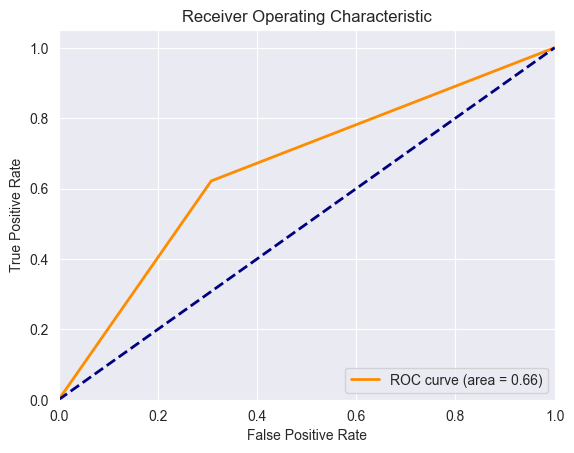

In [40]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

De acordo com o grafico ROC estámos bem distantes do ideal o que indica que o modelo não é bom.

# 7) Explique:

A) Explique com suas palavras regressão logistica.

B) Explique porque a regressão logistica é um modelo de classificação.

C) Explique quais pontos em comum a regressão logistica tem da regressão linear.



A) Regressão logistica é um modelo de machine learn usado classificação para prever probabilidades.
B) Ela transforma as entradas em probabilidades podendo ser veredadeira ou falsa.
C) Variaveis independentes, treianamento, buscam emcontrar relação entre as variais e podem ser ultilizadas para fazer previsões.